# Analysing and Plotting Burstiness Results

## Load libraries and data

In [18]:
# import libraries
import pickle
import statistics
import matplotlib.pyplot as plt
import re
import pandas as pd
import numpy as np
from collections import Counter
from datetime import datetime
from dateutil.relativedelta import relativedelta
from ast import literal_eval
from datetime import date
import matplotlib.dates as mdates
from matplotlib.lines import Line2D

In [19]:
def dates_col(df):
    new_col = []
    for x in df['dates']:
        l = literal_eval(x)
        new_col.append([datetime.strptime(date, "%Y-%m-%d") for date in l])

    return new_col

In [20]:
aus_keyword = pd.read_csv('./results/aus_keywords_BM_v2.csv')
aus_keyword['dates'] = dates_col(aus_keyword)

can_keyword = pd.read_csv('./results/can_keywords_BM_v2.csv')
can_keyword['dates'] = dates_col(can_keyword)

uk_keyword = pd.read_csv('./results/uk_keywords_BM_v2.csv')
uk_keyword['dates'] = dates_col(uk_keyword)

## Formatting Results - Table S3

In [21]:
def add_col_flag(df_in, flag1, flag2):
    df = df_in.copy()
    
    # 1. Define conditions using bitwise operators (&, |, ~)
    conditions = [(df[flag1] == 0) & (df[flag2] == 0),
    (df[flag1] == 0) & (df[flag2] == 1),
    (df[flag1] == 1) & (df[flag2] == 0),
    (df[flag1] == 1) & (df[flag2] == 1)]

    # 2. Define corresponding category outputs
    choices = ['black', 'red', 'blue', 'purple']

    # 3. Apply conditions and provide a default fallback value
    df['colour_flag'] = np.select(conditions, choices, default='Unknown')
    
    return df

In [22]:
aus_keyword = add_col_flag(aus_keyword, 'M-shuffle-flag-bonf', 'B-samp-flag-bonf')
can_keyword = add_col_flag(can_keyword, 'M-shuffle-flag-bonf', 'B-samp-flag-bonf')
uk_keyword = add_col_flag(uk_keyword, 'M-shuffle-flag-bonf', 'B-samp-flag-bonf')

aus_keyword2 = add_col_flag(aus_keyword, 'M-shuffle-flag-bonf', 'B-samp-flag-bonf-obsdates')
can_keyword2 = add_col_flag(can_keyword, 'M-shuffle-flag-bonf', 'B-samp-flag-bonf-obsdates')
uk_keyword2 = add_col_flag(uk_keyword, 'M-shuffle-flag-bonf', 'B-samp-flag-bonf-obsdates')

In [23]:
can_keyword2

,term,count,B,B-pval-samp,B-samp-flag,B-samp-flag-bonf,B-pval-samp-obsdates,B-samp-flag-obsdates,B-samp-flag-bonf-obsdates,M,M-pval-shuffle,M-shuffle-flag,M-shuffle-flag-bonf,dates,interevent-times,colour_flag
0,climate,115,0.112606,0.0072,1,1,0.1618,0,0,-0.093766,0.8236,0,0,"[2016-01-12 00:00:00, 2016-01-27 00:00:00, 201...","[15, 20, 22, 62, 1, 34, 85, 15, 14, 124, 3, 26...",black
1,health,509,0.232581,0.0000,1,1,0.5341,0,0,0.090531,0.0244,1,0,"[2016-01-08 00:00:00, 2016-02-02 00:00:00, 201...","[25, 13, 1, 2, 0, 1, 10, 7, 2, 7, 0, 13, 15, 1...",black
2,law,411,0.192341,0.0000,1,1,0.6964,0,0,0.101892,0.0247,1,0,"[2015-12-09 00:00:00, 2015-12-17 00:00:00, 201...","[8, 22, 25, 16, 11, 7, 9, 5, 0, 1, 2, 6, 9, 7,...",black
3,migration,102,0.060589,0.0693,0,0,0.5516,0,0,-0.035765,0.5867,0,0,"[2016-01-12 00:00:00, 2016-03-30 00:00:00, 201...","[78, 55, 30, 35, 56, 8, 60, 63, 1, 2, 69, 5, 3...",black


In [32]:
can_keyword['country'] = ['Canada']*len(can_keyword)
aus_keyword['country'] = ['Australia']*len(aus_keyword)
uk_keyword['country'] = ['UK']*len(uk_keyword)
concat = pd.concat([aus_keyword, can_keyword, uk_keyword], axis=0, ignore_index=True).drop(columns=['B-samp-flag', 'B-samp-flag-obsdates', 'M-shuffle-flag', 'dates', 'interevent-times', 'colour_flag'])
#print(concat['term', 'count', 'B', 'B-pval-samp', 'B-samp-flag-bonf', 'B-pval-samp-obsdates', 'B-samp-flag-bonf-obsdates'])

print(concat.round(3).to_latex(index = False, float_format="{:g}".format))

\begin{tabular}{lrrrrrrrrrl}
\toprule
term & count & B & B-pval-samp & B-samp-flag-bonf & B-pval-samp-obsdates & B-samp-flag-bonf-obsdates & M & M-pval-shuffle & M-shuffle-flag-bonf & country \\
\midrule
climate & 171 & 0.254 & 0 & 1 & 0.033 & 0 & 0.205 & 0.008 & 1 & Australia \\
health & 766 & 0.508 & 0 & 1 & 0.018 & 0 & -0.026 & 0.75 & 0 & Australia \\
law & 737 & 0.5 & 0 & 1 & 0.015 & 0 & -0.045 & 0.914 & 0 & Australia \\
migration & 200 & 0.291 & 0 & 1 & 0.006 & 1 & 0.143 & 0.031 & 0 & Australia \\
climate & 115 & 0.113 & 0.007 & 1 & 0.162 & 0 & -0.094 & 0.824 & 0 & Canada \\
health & 509 & 0.233 & 0 & 1 & 0.534 & 0 & 0.091 & 0.024 & 0 & Canada \\
law & 411 & 0.192 & 0 & 1 & 0.696 & 0 & 0.102 & 0.025 & 0 & Canada \\
migration & 102 & 0.061 & 0.069 & 0 & 0.552 & 0 & -0.036 & 0.587 & 0 & Canada \\
climate & 759 & 0.37 & 0 & 1 & 0 & 1 & 0.133 & 0.01 & 1 & UK \\
health & 5323 & 0.622 & 0 & 1 & 0 & 1 & -0.005 & 0.746 & 0 & UK \\
law & 6760 & 0.659 & 0 & 1 & 0 & 1 & 0.005 & 0.147 & 0 & U

## Figure 6

In [25]:
def BMplot_sing4(df, df2, df3, title=None, ax=None):

    if ax is None:
        fig, ax = plt.subplots(figsize=(7, 5))

    xmin, xmax, ymin, ymax = -1, 1, -1, 1
    ticks_frequency = 1
    marg = 0.05

    ax.set(
        xlim=(xmin-marg, xmax+marg),
        ylim=(ymin-marg, ymax+marg),
        aspect='equal'
    )
    
    #ax.set_anchor('W')

    ax.spines['bottom'].set_position('zero')
    ax.spines['left'].set_position('zero')
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

    ax.set_xlabel(r'Burstiness, $B$', size=14, labelpad=-36, x=1.03)
    ax.set_ylabel(r'Memory, $M$', size=14, labelpad=-21, y=1.02, rotation=0)

    x_ticks = np.arange(xmin, xmax + 1, ticks_frequency)
    y_ticks = np.arange(ymin, ymax + 1, ticks_frequency)

    ax.set_xticks(x_ticks[x_ticks != 0])
    ax.set_yticks(y_ticks[y_ticks != 0])

    ax.set_xticks(np.arange(xmin, xmax + 1), minor=True)
    ax.set_yticks(np.arange(ymin, ymax + 1), minor=True)
    
    ax.tick_params(axis='both', labelsize=12)

    ax.scatter(df['B'], df['M'],
               facecolors='none',
               edgecolors=df['colour_flag'],
               marker='o', s=50)

    ax.scatter(df2['B'], df2['M'],
               facecolors='none',
               edgecolors=df2['colour_flag'],
               marker='^', s=50)

    ax.scatter(df3['B'], df3['M'],
               facecolors='none',
               edgecolors=df3['colour_flag'],
               marker='p', s=50)

    color_handles = [
        Line2D([0],[0],marker="s",color="w",markerfacecolor="black",markersize=10,label="None"),
        # Line2D([0],[0],marker="s",color="w",markerfacecolor="blue",markersize=10,label="M only"),
        Line2D([0],[0],marker="s",color="w",markerfacecolor="red",markersize=10,label="B only"),
        Line2D([0],[0],marker="s",color="w",markerfacecolor="purple",markersize=10,label="Both")
    ]

    shape_handles = [
        Line2D([0],[0],marker="o",color="w",markerfacecolor="gray",markersize=10,label="Australia"),
        Line2D([0],[0],marker="^",color="w",markerfacecolor="gray",markersize=10,label="Canada"),
        Line2D([0],[0],marker="p",color="w",markerfacecolor="gray",markersize=10,label="UK")
    ]

    color_header = Line2D([], [], color="none", label=r"$\bf{Significance}$")
    shape_header = Line2D([], [], color="none", label=r"$\bf{Country}$")

    all_handles = [color_header] + color_handles + [shape_header] + shape_handles

    ax.legend(handles=all_handles, loc="upper left", fontsize = 12)

    if title:
        # ax.set_title(title)
        ax.text(0.5, 1.08, title, transform=ax.transAxes, ha='center', va='bottom', fontsize=12)

    return ax

In [26]:
import matplotlib.dates as mdates

def plot_date(dates, title_in=None, ax=None, col = 'blue'):

    if ax is None:
        fig, ax = plt.subplots(figsize=(8, 4))

    ax.eventplot(
        dates,
        orientation='horizontal',
        linelengths=0.5,
        colors=col
    )
    
    # add election to event plots?
    
    # show only years
    ax.xaxis.set_major_locator(mdates.YearLocator(2))
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))

    # ax.set_xlabel('Date', fontsize=11, labelpad=10)
    ax.yaxis.set_visible(False)

    if title_in:
        ax.set_title(title_in, size = 14)

    return ax

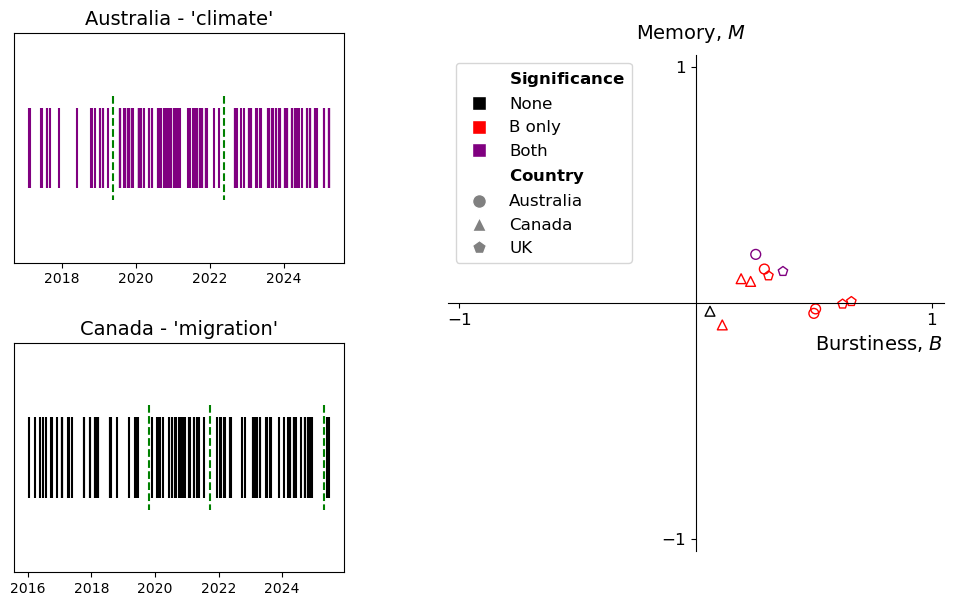

In [27]:
aus_elections =[datetime(2022, 5, 21, 0, 0, 0), 
 datetime(2019, 5, 18, 0, 0, 0)] # datetime(2016, 7, 2, 0, 0, 0) # datetime(2025, 5, 3, 0, 0, 0), 

can_elections = [datetime(2025, 4, 28, 0, 0, 0), 
                 datetime(2021, 9, 20, 0, 0, 0), 
                 datetime(2019, 10, 21, 0, 0, 0)] # datetime(2015, 10, 19, 0, 0, 0)

uk_elections = [datetime(2024, 7, 4, 0, 0, 0),
datetime(2019, 12, 12, 0, 0, 0),
datetime(2017, 6, 8, 0, 0, 0),
datetime(2015, 5, 7, 0, 0, 0)] #datetime(2010, 5, 6, 0, 0, 0)


import matplotlib.dates as mdates

def plot_date(dates, election_dates, title_in=None, ax=None, col = 'blue'):

    if ax is None:
        fig, ax = plt.subplots(figsize=(8, 4))

    ax.eventplot(
        dates,
        orientation='horizontal',
        linelengths=1,
        colors=col
    )
    
    ax.eventplot(
        election_dates,
        orientation='horizontal',
        linelengths=1.3,
        colors='green',
        linestyles='--',
    )
    
    # add election to event plots?
    
    # show only years
    ax.xaxis.set_major_locator(mdates.YearLocator(2))
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))

    # ax.set_xlabel('Date', fontsize=11, labelpad=10)
    ax.yaxis.set_visible(False)

    if title_in:
        ax.set_title(title_in, size = 14)

    return ax


from matplotlib import gridspec
import matplotlib.pyplot as plt

fig = plt.figure(figsize=(12, 7))
#fig = plt.figure(figsize=(12, 7), constrained_layout=True)

gs = gridspec.GridSpec(
    nrows=2,
    ncols=2,
    width_ratios=[1, 1.5],   # right panel slightly wider
    height_ratios=[1, 1],
    wspace=0.25,
    hspace=0.35
    #figure=fig
)


# Left column: stacked event plots
ax_top = fig.add_subplot(gs[0, 0])
ax_bottom = fig.add_subplot(gs[1, 0])
# Right column: B-M plot spanning both rows
ax_right = fig.add_subplot(gs[:, 1])

plot_date(aus_keyword.iloc[0]['dates'], aus_elections, "Australia - 'climate'", ax=ax_top, col = 'purple')
plot_date(can_keyword.iloc[3]['dates'], can_elections, "Canada - 'migration'", ax=ax_bottom, col = 'black')
BMplot_sing4(aus_keyword, can_keyword, uk_keyword, ax=ax_right)
ax_right.xaxis.set_label_coords(0.87, 0.44)
#BMplot_sing4(aus_keyword2, can_keyword2, uk_keyword2, ax=ax_right)
#plt.savefig('../figures/burstiness-3panel-keywords-og-B-method-v2-elections-flipped2.png', dpi = 300, bbox_inches='tight')

#plt.tight_layout()
plt.show()